# Análisis exploratorio de datos - Steam

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import json
from collections import Counter
from IPython.display import display

from collections import Counter
from IPython.display import display


# Dataset principal
df = pd.read_csv("C:/Users/luisr/OneDrive/Desktop/ITAM/Tercer Semestre/Aprendizaje de Máquina/ProyectoFinal/steam_games.csv")

# Dataset de reviews
df_reviews = pd.read_csv("C:/Users/luisr/OneDrive/Desktop/ITAM/Tercer Semestre/Aprendizaje de Máquina/ProyectoFinal/steam_games_reviews.csv")

print("DATASET PRINCIPAL")
print("Dimensiones:", df.shape)
display(df.head())

print("\nDATASET DE REVIEWS")
print("Dimensiones:", df_reviews.shape)
display(df_reviews.head())

C:\Users\luisr\AppData\Local\Temp\ipykernel_28616\3989406337.py:15: DtypeWarning: Columns (30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("C:/Users/luisr/OneDrive/Desktop/ITAM/Tercer Semestre/Aprendizaje de Máquina/ProyectoFinal/steam_games.csv")


DATASET PRINCIPAL
Dimensiones: (150643, 42)


,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,linux,header_image,screenshots,movies,website,support_url,support_email,metacritic_url,steam_store_available,steam_spy_available
0,1265390,EllrLand,2020-04-28,0.0,free,0 - 20000,"[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Adventure"", ""Strategy""]","[""Single-player"", ""Family Sharing""]",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://www.scsghd.com/,https://www.scsghd.com/,Kisence@scsghd.com,NaN,True,True
1,1266480,MiNNaDe Counter Fight,2020-05-01,0.0,free,0 - 20000,"[""Tricol Co., Ltd.""]","[""Tricol Co., Ltd.""]","[""Action"", ""Casual"", ""Indie"", ""Early Access""]","[""Single-player"", ""Multi-player"", ""Co-op"", ""Sh...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://www.tricol.jp/product/minnade-counter-...,https://www.tricol.jp/product/minnade-counter-...,contact@vr.tricol.jp,NaN,True,True
2,1289500,BattleParty,2020-04-27,0.0,free,0 - 20000,"[""TeamNova""]","[""TeamNova""]","[""Action"", ""Adventure"", ""Free To Play"", ""Indie...","[""Single-player"", ""Multi-player"", ""Co-op"", ""LA...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://discord.gg/Und8m8q,https://discord.gg/Und8m8q,direction@teamnova.fr,NaN,True,True
3,1318140,BookConverter,2020-05-15,0.0,free,0 - 0,[],[],[],"[""Family Sharing""]",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],NaN,NaN,NaN,NaN,True,True
4,1342260,SAMURAI SHODOWN,2021-06-14,0.0,free,0 - 0,"[""SNK CORPORATION""]","[""SNK CORPORATION""]","[""Action""]","[""Single-player"", ""Multi-player"", ""PvP"", ""Onli...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://www.snk-corp.co.jp/official/samuraispi...,https://www.snk-corp.co.jp/faq/inquiry/?post_i...,info@snk-corp.co.jp,NaN,True,True



DATASET DE REVIEWS
Dimensiones: (13568, 3)


,app_id,name,reviews
0,1741900,You VS Drugs,"“It's a very novel and interesting idea, it im..."
1,2334220,Home Sweet Home : Online,“Experience the Balanced PvP Battles With Home...
2,2488620,F1® 24,"“'F1 24 is, without a doubt, the best F1 racin..."
3,1245780,Mirage,“An advanced VR sex simulator with realistic g...
4,1247290,GameGuru MAX,“One of the easiest and most powerful game cre...


## Preprocesamiento

In [3]:

# Columnas que queremos conservar
columnas_conservar = [
    "app_id",
    "name",
    "release_date",
    "price",
    "estimated_owners",
    "developers",
    "publishers",
    "genres",
    "categories",
    "positive",
    "negative",
    "recommendations",
    "average_playtime_forever",
    "steam_store_available",
    "steam_spy_available"
]

# Crear una copia conservando únicamente estas columnas
df_preprocesado = df[columnas_conservar].copy()

# Verificación

print(f"Dimensiones originales: {df.shape}")
print(f"Dimensiones después del preprocesamiento: {df_preprocesado.shape}")

print("\nColumnas conservadas:")
print(df_preprocesado.columns.tolist())

# Primeros 5 registros

display(df_preprocesado.head())

Dimensiones originales: (150643, 42)
Dimensiones después del preprocesamiento: (150643, 15)

Columnas conservadas:
['app_id', 'name', 'release_date', 'price', 'estimated_owners', 'developers', 'publishers', 'genres', 'categories', 'positive', 'negative', 'recommendations', 'average_playtime_forever', 'steam_store_available', 'steam_spy_available']


,app_id,name,release_date,price,estimated_owners,developers,publishers,genres,categories,positive,negative,recommendations,average_playtime_forever,steam_store_available,steam_spy_available
0,1265390,EllrLand,2020-04-28,0.0,0 - 20000,"[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Adventure"", ""Strategy""]","[""Single-player"", ""Family Sharing""]",38,28,0.0,0,True,True
1,1266480,MiNNaDe Counter Fight,2020-05-01,0.0,0 - 20000,"[""Tricol Co., Ltd.""]","[""Tricol Co., Ltd.""]","[""Action"", ""Casual"", ""Indie"", ""Early Access""]","[""Single-player"", ""Multi-player"", ""Co-op"", ""Sh...",12,6,0.0,0,True,True
2,1289500,BattleParty,2020-04-27,0.0,0 - 20000,"[""TeamNova""]","[""TeamNova""]","[""Action"", ""Adventure"", ""Free To Play"", ""Indie...","[""Single-player"", ""Multi-player"", ""Co-op"", ""LA...",17,9,0.0,0,True,True
3,1318140,BookConverter,2020-05-15,0.0,0 - 0,[],[],[],"[""Family Sharing""]",0,0,0.0,0,True,True
4,1342260,SAMURAI SHODOWN,2021-06-14,0.0,0 - 0,"[""SNK CORPORATION""]","[""SNK CORPORATION""]","[""Action""]","[""Single-player"", ""Multi-player"", ""PvP"", ""Onli...",0,0,1587.0,0,True,True


In [4]:

# Calcular el total de reseñas
total_reviews = (
    df_preprocesado["positive"] +
    df_preprocesado["negative"]
)

# Calcular proporción de reseñas positivas
proporcion = (
    df_preprocesado["positive"] /
    total_reviews.replace(0, np.nan)
)

# Insertar inmediatamente después de "negative"
posicion = df_preprocesado.columns.get_loc("negative") + 1

# Si la columna ya existe, eliminarla para evitar duplicados
if "positive_review_proportion" in df_preprocesado.columns:
    df_preprocesado.drop(
        columns=["positive_review_proportion"],
        inplace=True
    )
    posicion = df_preprocesado.columns.get_loc("negative") + 1

df_preprocesado.insert(
    posicion,
    "positive_review_proportion",
    proporcion
)


display(
    df_preprocesado[
        ["positive", "negative", "positive_review_proportion"]
    ].head(10)
)

,positive,negative,positive_review_proportion
0,38,28,0.575758
1,12,6,0.666667
2,17,9,0.653846
3,0,0,NaN
4,0,0,NaN
5,0,0,NaN
6,0,0,NaN
7,0,0,NaN
8,2,0,1.000000
9,1,0,1.000000


In [5]:

# Análisis de variables categóricas 

columnas_categoricas = [
    "developers",
    "publishers",
    "genres",
    "categories"
]


# Normalizamos listas y diccionarios


def convertir_lista(valor):

    def extraer_etiquetas(elemento):

        # Caso 1: valores faltantes
        if elemento is None:
            return []

        # Caso 2: diccionarios
        # Extraer únicamente el nombre de la categoría
        if isinstance(elemento, dict):

            for clave in ["description", "name", "label"]:

                if clave in elemento:
                    return extraer_etiquetas(elemento[clave])

            return []

        # Caso 3: listas, tuplas o conjuntos
        if isinstance(elemento, (list, tuple, set)):

            etiquetas = []

            for item in elemento:
                etiquetas.extend(extraer_etiquetas(item))

            return etiquetas

        # Caso 4: cadenas de texto
        if isinstance(elemento, str):

            texto = elemento.strip()

            if texto.lower() in ["", "nan", "none", "null"]:
                return []

            # Detectar listas o diccionarios guardados como texto
            if texto.startswith(("[", "{")):

                try:
                    convertido = ast.literal_eval(texto)

                    return extraer_etiquetas(convertido)

                except (ValueError, SyntaxError):

                    try:
                        convertido = json.loads(texto)

                        return extraer_etiquetas(convertido)

                    except (ValueError, TypeError):
                        pass

            # Categoría como texto normal
            return [texto]

        # Caso 5: valores numéricos o faltantes
        try:
            if pd.isna(elemento):
                return []
        except (ValueError, TypeError):
            pass

        return [str(elemento).strip()]

    # Extraer categorías
    etiquetas = extraer_etiquetas(valor)

    # Eliminar duplicados dentro de cada videojuego
    # Mantener el orden original
    return list(dict.fromkeys(etiquetas))



# Conteo de categorías


resumen = []
tablas_frecuencia = {}

for columna in columnas_categoricas:

    # Convertir registros a listas normalizadas
    listas = df_preprocesado[columna].apply(convertir_lista)

    # Contar categorías individuales
    contador = Counter()

    for lista in listas:
        contador.update(lista)

    # Tabla de frecuencias
    frecuencias = pd.DataFrame(
        contador.items(),
        columns=["Categoria", "Frecuencia"]
    ).sort_values(
        by="Frecuencia",
        ascending=False
    ).reset_index(drop=True)

    tablas_frecuencia[columna] = frecuencias

    # Guardar resumen
    resumen.append({
        "Variable": columna,
        "Categorias_unicas": len(contador),
        "Registros_con_datos": (listas.apply(len) > 0).sum(),
        "Registros_vacios": (listas.apply(len) == 0).sum(),
        "Total_asignaciones": sum(contador.values())
    })

    print(f"VARIABLE: {columna.upper()}")
    

    print(f"Categorías únicas: {len(contador):,}")

    print("\n20 categorías más frecuentes:")
    display(frecuencias.head(20))



# Resumen General


df_resumen_categorias = pd.DataFrame(resumen)

print("\nRESUMEN GENERAL DE VARIABLES CATEGÓRICAS")

display(df_resumen_categorias)

VARIABLE: DEVELOPERS
Categorías únicas: 94,960

20 categorías más frecuentes:


,Categoria,Frecuencia
0,EroticGamesClub,237
1,Choice of Games,186
2,IR Studio,171
3,Gamesforgames,157
4,Laush Dmitriy Sergeevich,153
5,Bully Revenge Studios,150
6,Creobit,145
7,Boogygames Studios,145
8,Tero Lunkka,137
9,Cyber Keks,137


VARIABLE: PUBLISHERS
Categorías únicas: 80,574

20 categorías más frecuentes:


,Categoria,Frecuencia
0,BFG Entertainment,555
1,PlayWay S.A.,337
2,8floor,268
3,EroticGamesClub,237
4,Gamersky Games,232
5,Kagura Games,223
6,Strategy First,214
7,Conglomerate 5,197
8,HH-Games,196
9,Electronic Arts,196


VARIABLE: GENRES
Categorías únicas: 43

20 categorías más frecuentes:


,Categoria,Frecuencia
0,Indie,101157
1,Casual,63917
2,Action,55530
3,Adventure,53733
4,Simulation,31793
5,Strategy,29464
6,RPG,25699
7,Free To Play,15425
8,Early Access,14637
9,Sports,5852


VARIABLE: CATEGORIES
Categorías únicas: 98

20 categorías más frecuentes:


,Categoria,Frecuencia
0,Single-player,134727
1,Family Sharing,126725
2,Steam Achievements,71596
3,Steam Cloud,41226
4,Full controller support,32024
5,Multi-player,25921
6,Playable without Timed Input,19355
7,Custom Volume Controls,18434
8,PvP,15933
9,Partial Controller Support,15784



RESUMEN GENERAL DE VARIABLES CATEGÓRICAS


,Variable,Categorias_unicas,Registros_con_datos,Registros_vacios,Total_asignaciones
0,developers,94960,142185,8458,155006
1,publishers,80574,141733,8910,147848
2,genres,43,142209,8434,410015
3,categories,98,141681,8962,712126


## Exploración Estructural del Dataset (con reducción de variables)

In [6]:

# Trabajamos con una copia para conservar el original

df_eda = df_preprocesado.copy()

# dimensión del dataset

print("DIMENSIONES DEL DATASET")

print(f"Número de registros: {df_eda.shape[0]:,}")
print(f"Número de variables: {df_eda.shape[1]}")

# Primeros registros

print("\nPRIMEROS 5 REGISTROS")

display(df_eda.head())

#  Tipos de datos

print("\nTIPOS DE DATOS")

display(
    pd.DataFrame({
        "Variable": df_eda.columns,
        "Tipo": df_eda.dtypes.astype(str).values
    })
)

# Valores faltantes

print("\nANÁLISIS DE VALORES FALTANTES")

resumen_nulos = pd.DataFrame({
    "Variable": df_eda.columns,
    "Nulos": df_eda.isnull().sum().values,
    "Porcentaje_nulos": (
        df_eda.isnull().mean().values * 100
    )
})

resumen_nulos = resumen_nulos.sort_values(
    by="Porcentaje_nulos",
    ascending=False
)

display(resumen_nulos.round(2))

# Listas vacías en variables categóticas

print("\nLISTAS VACÍAS EN VARIABLES CATEGÓRICAS")

columnas_categoricas = [
    "developers",
    "publishers",
    "genres",
    "categories"
]

resumen_vacios = []

for columna in columnas_categoricas:

    def es_lista_vacia(valor):
        if isinstance(valor, (list, tuple, set)):
            return len(valor) == 0
        if isinstance(valor, str):
            return valor.strip() in ["[]", ""]
        return False

    vacios = df_eda[columna].apply(es_lista_vacia).sum()

    resumen_vacios.append({
        "Variable": columna,
        "Listas_vacias": vacios,
        "Porcentaje": vacios / len(df_eda) * 100
    })

display(pd.DataFrame(resumen_vacios).round(2))

# Registros duplicados

print("\nREGISTROS DUPLICADOS")

# Convertir temporalmente a texto para permitir
# comparar columnas que contienen listas
duplicados = df_eda.astype(str).duplicated().sum()

print(f"Registros completamente duplicados: {duplicados:,}")

# Verificar identificadores de videojuegos
if "app_id" in df_eda.columns:

    duplicados_id = df_eda["app_id"].duplicated().sum()

    print(f"app_id duplicados: {duplicados_id:,}")

# Resumen general

print("\nRESUMEN GENERAL")

df_eda.info()

DIMENSIONES DEL DATASET
Número de registros: 150,643
Número de variables: 16

PRIMEROS 5 REGISTROS


,app_id,name,release_date,price,estimated_owners,developers,publishers,genres,categories,positive,negative,positive_review_proportion,recommendations,average_playtime_forever,steam_store_available,steam_spy_available
0,1265390,EllrLand,2020-04-28,0.0,0 - 20000,"[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Sichuan fruit Interactive Technology Co., Ltd""]","[""Adventure"", ""Strategy""]","[""Single-player"", ""Family Sharing""]",38,28,0.575758,0.0,0,True,True
1,1266480,MiNNaDe Counter Fight,2020-05-01,0.0,0 - 20000,"[""Tricol Co., Ltd.""]","[""Tricol Co., Ltd.""]","[""Action"", ""Casual"", ""Indie"", ""Early Access""]","[""Single-player"", ""Multi-player"", ""Co-op"", ""Sh...",12,6,0.666667,0.0,0,True,True
2,1289500,BattleParty,2020-04-27,0.0,0 - 20000,"[""TeamNova""]","[""TeamNova""]","[""Action"", ""Adventure"", ""Free To Play"", ""Indie...","[""Single-player"", ""Multi-player"", ""Co-op"", ""LA...",17,9,0.653846,0.0,0,True,True
3,1318140,BookConverter,2020-05-15,0.0,0 - 0,[],[],[],"[""Family Sharing""]",0,0,NaN,0.0,0,True,True
4,1342260,SAMURAI SHODOWN,2021-06-14,0.0,0 - 0,"[""SNK CORPORATION""]","[""SNK CORPORATION""]","[""Action""]","[""Single-player"", ""Multi-player"", ""PvP"", ""Onli...",0,0,NaN,1587.0,0,True,True



TIPOS DE DATOS


,Variable,Tipo
0,app_id,int64
1,name,object
2,release_date,object
3,price,float64
4,estimated_owners,object
5,developers,object
6,publishers,object
7,genres,object
8,categories,object
9,positive,int64



ANÁLISIS DE VALORES FALTANTES


,Variable,Nulos,Porcentaje_nulos
11,positive_review_proportion,67551,44.84
12,recommendations,52959,35.16
3,price,1425,0.95
2,release_date,82,0.05
1,name,16,0.01
5,developers,0,0.00
4,estimated_owners,0,0.00
0,app_id,0,0.00
7,genres,0,0.00
6,publishers,0,0.00



LISTAS VACÍAS EN VARIABLES CATEGÓRICAS


,Variable,Listas_vacias,Porcentaje
0,developers,8449,5.61
1,publishers,8849,5.87
2,genres,8434,5.60
3,categories,8962,5.95



REGISTROS DUPLICADOS
Registros completamente duplicados: 0
app_id duplicados: 0

RESUMEN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150643 entries, 0 to 150642
Data columns (total 16 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   app_id                      150643 non-null  int64  
 1   name                        150627 non-null  object 
 2   release_date                150561 non-null  object 
 3   price                       149218 non-null  float64
 4   estimated_owners            150643 non-null  object 
 5   developers                  150643 non-null  object 
 6   publishers                  150643 non-null  object 
 7   genres                      150643 non-null  object 
 8   categories                  150643 non-null  object 
 9   positive                    150643 non-null  int64  
 10  negative                    150643 non-null  int64  
 11  positive_review_proportion  8309

## Estadísticas descriptivas básicas

In [7]:
# Seleccionar variables numéricas. Excluimos app_id porque es un identificador, no una variable cuantitativa para análisis estadístico.

columnas_numericas = [
    "price",
    "positive",
    "negative",
    "recommendations",
    "average_playtime_forever",
    "positive_review_proportion"
]

# Convertir a formato numérico sin modificar df_eda
df_num = df_eda[columnas_numericas].apply(
    pd.to_numeric, errors="coerce"
)


# Estadísticas descriptivas


resumen_estadistico = pd.DataFrame({
    "Conteo": df_num.count(),
    "Media": df_num.mean(),
    "Mediana": df_num.median(),
    "Moda": df_num.apply(
        lambda x: x.mode().iloc[0]
        if not x.mode().empty else np.nan
    ),
    "Mínimo": df_num.min(),
    "Máximo": df_num.max(),
    "Rango": df_num.max() - df_num.min(),
    "Varianza": df_num.var(),
    "Desv. estándar": df_num.std(),
    "P5": df_num.quantile(0.05),
    "P25": df_num.quantile(0.25),
    "P50": df_num.quantile(0.50),
    "P75": df_num.quantile(0.75),
    "P95": df_num.quantile(0.95),
    "Asimetría": df_num.skew(),
    "Curtosis": df_num.kurt()
})


print("ESTADÍSTICAS DESCRIPTIVAS")


display(resumen_estadistico.round(2))


# Conteo y proporción de valores iguales a cero


resumen_ceros = pd.DataFrame({
    "Variable": columnas_numericas,
    "Cantidad_ceros": [
        (df_num[col] == 0).sum()
        for col in columnas_numericas
    ],
    "Porcentaje_ceros": [
        (df_num[col] == 0).mean() * 100
        for col in columnas_numericas
    ]
})

print("ANÁLISIS DE VALORES IGUALES A CERO")


display(resumen_ceros.round(2))

ESTADÍSTICAS DESCRIPTIVAS


,Conteo,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desv. estándar,P5,P25,P50,P75,P95,Asimetría,Curtosis
price,149218,8.92,4.99,0.0,0.0,107500.0,107500.0,1.567752e+05,395.95,0.00,0.99,4.99,9.99,19.99,268.62,72820.33
positive,150643,851.94,1.00,0.0,0.0,7642084.0,7642084.0,6.428054e+08,25353.61,0.00,0.00,1.00,22.00,750.00,196.92,55572.56
negative,150643,137.81,0.00,0.0,0.0,1173003.0,1173003.0,2.349476e+07,4847.14,0.00,0.00,0.00,6.00,163.00,174.05,37688.91
recommendations,97684,1279.22,0.00,0.0,0.0,5179195.0,5179195.0,6.661753e+08,25810.37,0.00,0.00,0.00,0.00,1732.85,104.62,17664.44
average_playtime_forever,150643,55.62,0.00,0.0,0.0,359665.0,359665.0,3.118561e+06,1765.94,0.00,0.00,0.00,0.00,52.00,131.60,21865.21
positive_review_proportion,83092,0.76,0.82,1.0,0.0,1.0,1.0,6.000000e-02,0.24,0.26,0.65,0.82,0.94,1.00,-1.32,1.57


ANÁLISIS DE VALORES IGUALES A CERO


,Variable,Cantidad_ceros,Porcentaje_ceros
0,price,28702,19.05
1,positive,70162,46.58
2,negative,83095,55.16
3,recommendations,75295,49.98
4,average_playtime_forever,141455,93.90
5,positive_review_proportion,2611,1.73


## Análisis univariado numérico

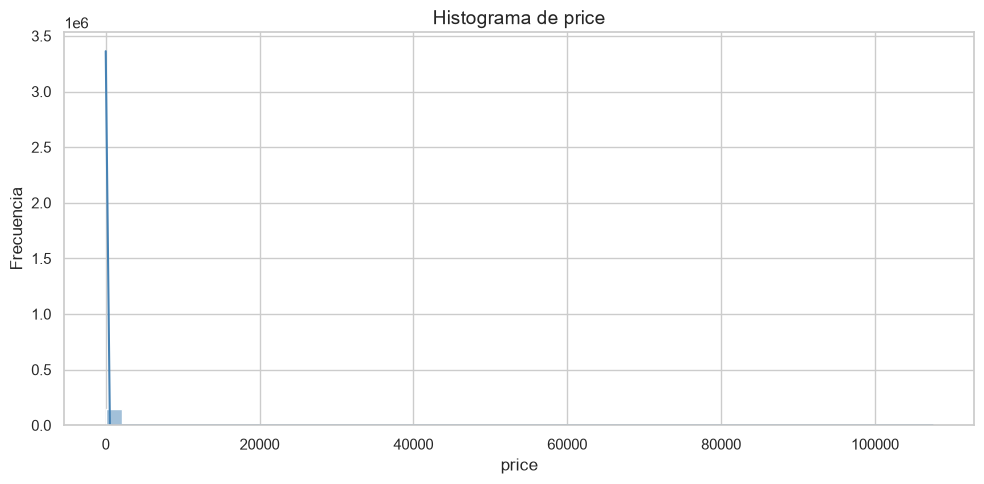

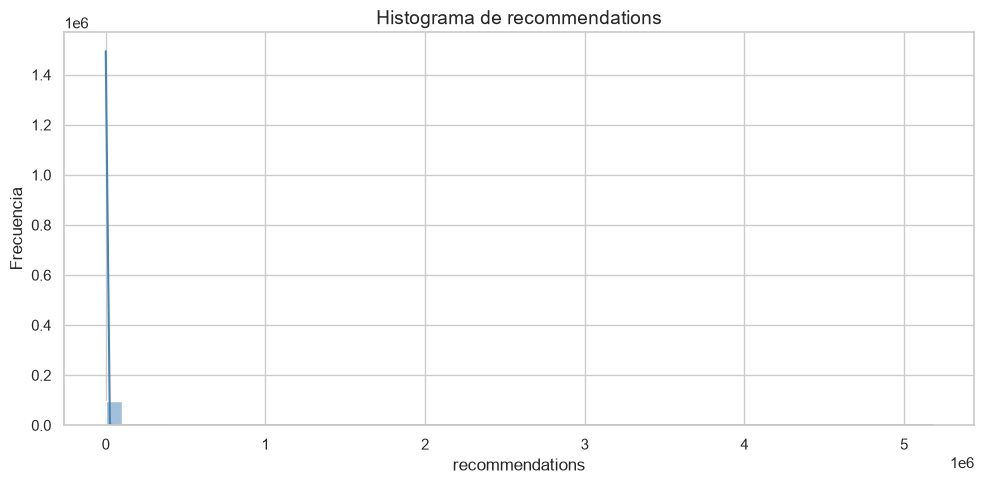

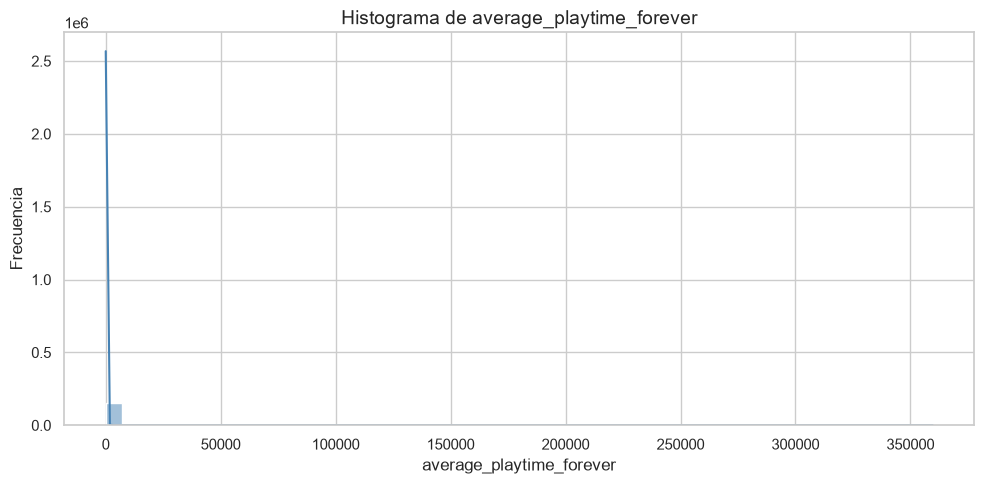

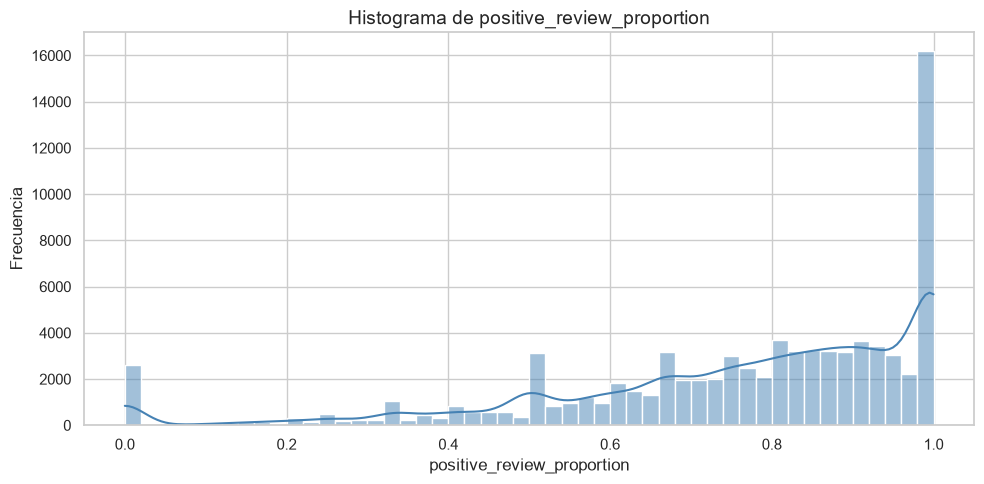

In [8]:

# Histogramas

columnas_numericas = [
    "price",
    "recommendations",
    "average_playtime_forever",
    "positive_review_proportion"
]

sns.set_theme(style="whitegrid")

for columna in columnas_numericas:

    datos = pd.to_numeric(
        df_eda[columna], errors="coerce"
    ).dropna()

    plt.figure(figsize=(10, 5))

    sns.histplot(
        datos,
        bins=50,
        kde=True,
        color="steelblue"
    )

    plt.title(f"Histograma de {columna}", fontsize=14)
    plt.xlabel(columna)
    plt.ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()

## Análisis de variables categóricas

In [9]:
# Frecuencia de variables multi-etiqueta

columnas_categoricas = [
    "developers",
    "publishers",
    "genres",
    "categories"
]

# Función para convertir valores a listas
def convertir_lista(valor):

    if isinstance(valor, (list, tuple, set)):
        lista = list(valor)

    elif isinstance(valor, str):
        try:
            lista = ast.literal_eval(valor)
        except (ValueError, SyntaxError):
            lista = [valor]

    elif pd.isna(valor):
        return []

    else:
        lista = [valor]

    if not isinstance(lista, (list, tuple, set)):
        lista = [lista]

    # Eliminar elementos vacíos y duplicados
    return list(dict.fromkeys(
        str(x).strip()
        for x in lista
        if x is not None
        and str(x).strip()
        and str(x).strip().lower() not in ["nan", "none"]
    ))


# Diccionario para almacenar resultados
frecuencias_categoricas = {}

n_juegos = len(df_eda)

for columna in columnas_categoricas:

    # Convertir cada registro a lista
    listas = df_eda[columna].apply(convertir_lista)

    # Separar etiquetas individuales
    etiquetas = listas.explode().dropna()

    # Frecuencia absoluta
    frecuencia = etiquetas.value_counts()

    # Frecuencia relativa respecto al total de juegos
    proporcion = frecuencia / n_juegos * 100

    tabla = pd.DataFrame({
        "Frecuencia": frecuencia,
        "Porcentaje_juegos": proporcion
    })

    frecuencias_categoricas[columna] = tabla

    
    print(f"VARIABLE: {columna.upper()}")
    

    print(f"Categorías únicas: {len(frecuencia):,}")

    print("\n20 etiquetas más frecuentes:")

    display(tabla.head(20).round(2))

VARIABLE: DEVELOPERS
Categorías únicas: 94,961

20 etiquetas más frecuentes:


,Frecuencia,Porcentaje_juegos
developers,,
EroticGamesClub,237,0.16
Choice of Games,186,0.12
IR Studio,171,0.11
Gamesforgames,157,0.10
Laush Dmitriy Sergeevich,153,0.10
Bully Revenge Studios,150,0.10
Boogygames Studios,145,0.10
Creobit,145,0.10
Cyber Keks,137,0.09


VARIABLE: PUBLISHERS
Categorías únicas: 80,575

20 etiquetas más frecuentes:


,Frecuencia,Porcentaje_juegos
publishers,,
BFG Entertainment,555,0.37
PlayWay S.A.,337,0.22
8floor,268,0.18
EroticGamesClub,237,0.16
Gamersky Games,232,0.15
Kagura Games,223,0.15
Strategy First,214,0.14
Conglomerate 5,197,0.13
Electronic Arts,196,0.13


VARIABLE: GENRES
Categorías únicas: 67

20 etiquetas más frecuentes:


,Frecuencia,Porcentaje_juegos
genres,,
Indie,60861,40.40
Casual,40788,27.08
"{'id': '23', 'description': 'Indie'}",40296,26.75
Adventure,34173,22.68
Action,33247,22.07
"{'id': '4', 'description': 'Casual'}",23129,15.35
"{'id': '1', 'description': 'Action'}",22283,14.79
"{'id': '25', 'description': 'Adventure'}",19560,12.98
Simulation,19289,12.80


VARIABLE: CATEGORIES
Categorías únicas: 156

20 etiquetas más frecuentes:


,Frecuencia,Porcentaje_juegos
categories,,
Single-player,82760,54.94
Family Sharing,72485,48.12
"{'id': 62, 'description': 'Family Sharing'}",54240,36.01
"{'id': 2, 'description': 'Single-player'}",51967,34.50
Steam Achievements,41320,27.43
"{'id': 22, 'description': 'Steam Achievements'}",30276,20.10
Steam Cloud,22670,15.05
Full controller support,18792,12.47
"{'id': 23, 'description': 'Steam Cloud'}",18556,12.32
